# Etapa média da GOL — pandas, numpy, matplotlib e seaborn na prática

Este notebook refaz a análise de `analise_etapa_media_gol.py` (SPEC-013) passo a passo,
mas com um objetivo diferente do script: **ensinar** pandas, numpy, matplotlib e seaborn
através de uma análise real, não de dados de brinquedo.

**O que já sabemos sobre o problema** (herdado do script de produção):
- Fonte: `basica_curated_deep` em `db/anac_basica.sqlite` (SPEC-012).
- Recorte padrão desta linha de análise: só etapas `PASSAGEIRO` da GOL (`GLO`), exclui `CARGUEIRO`.
- Pergunta: como se comporta a duração média de etapa (`nr_horas_voadas`) no tempo, por frota e por base.

**Como o notebook está organizado**: cada seção resolve um pedaço da análise e, ao resolver,
apresenta um conceito de biblioteca. A ordem segue a lógica da análise (carregar → explorar →
agregar no tempo → agregar por categoria → localizar HUBs), não uma lista arbitrária de features.

Roda com o kernel do ambiente `pesquisa-azul` (`conda run -n pesquisa-azul jupyter ...`).

## 1. Importações

Quatro bibliotecas, quatro papéis:

- **pandas**: estrutura de dados tabular (`DataFrame`), leitura de SQL/CSV, agregações.
- **numpy**: arrays e operações vetorizadas — pandas é construído em cima do numpy.
- **matplotlib**: motor de desenho de baixo nível. Controle total, mais código.
- **seaborn**: camada estatística sobre o matplotlib. Menos código para gráficos categóricos
  e agregados, porque ele sabe agregar e mapear categorias sozinho.

In [1]:
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

REPO_ROOT = Path.cwd().resolve().parents[1]
DB_PATH = REPO_ROOT / "db" / "anac_basica.sqlite"
assert DB_PATH.exists(), f"banco nao encontrado em {DB_PATH}"
DB_PATH

PosixPath('/home/bruno/Projetos/learn-microdados_anac_dados/db/anac_basica.sqlite')

## 2. Carregando dados com pandas: `read_sql_query`

`pd.read_sql_query` roda uma query SQL e devolve o resultado já como `DataFrame` — não precisa
buscar linha a linha como faria com o cursor puro do `sqlite3`. `parse_dates` converte a coluna
de texto em `datetime64`, o que é obrigatório para tudo que vem depois (resample por mês).

In [2]:
QUERY = """
    SELECT
        dt_partida_real, sg_equipamento_icao, ds_natureza_tipo_linha,
        sg_icao_origem, sg_icao_destino, nr_horas_voadas, km_distancia
    FROM basica_curated_deep
    WHERE sg_empresa_icao = 'GLO'
      AND ds_servico_tipo_linha = 'PASSAGEIRO'
      AND dt_partida_real BETWEEN ? AND ?
"""

con = sqlite3.connect(DB_PATH)
df = pd.read_sql_query(
    QUERY, con, params=("2021-01-01", "2026-07-31"), parse_dates=["dt_partida_real"]
)
con.close()

print(f"{len(df):,} etapas carregadas".replace(",", "."))
df.head()

1.156.949 etapas carregadas


,dt_partida_real,sg_equipamento_icao,ds_natureza_tipo_linha,sg_icao_origem,sg_icao_destino,nr_horas_voadas,km_distancia
0,2021-01-01,B738,DOMÉSTICA,SBAR,SBGR,2.50000,1705
1,2021-01-01,B738,DOMÉSTICA,SBAR,SBGR,2.68333,1705
2,2021-01-01,B738,DOMÉSTICA,SBJP,SBGR,3.20000,2190
3,2021-01-01,B738,DOMÉSTICA,SBJP,SBBR,2.70000,1713
4,2021-01-01,B738,DOMÉSTICA,SBJP,SBSV,1.48333,739


### Explorando o `DataFrame` antes de qualquer gráfico

Três comandos que valem para qualquer análise nova, antes de escrever a primeira linha de plot:

- `.info()`: quantas linhas, quais tipos, onde tem nulo.
- `.describe()`: distribuição das colunas numéricas (média, desvio, quartis).
- `.dtypes`: confirma que `dt_partida_real` virou `datetime64`, não ficou string.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1156949 entries, 0 to 1156948
Data columns (total 7 columns):
 #   Column                  Non-Null Count    Dtype         
---  ------                  --------------    -----         
 0   dt_partida_real         1156949 non-null  datetime64[ns]
 1   sg_equipamento_icao     1156949 non-null  object        
 2   ds_natureza_tipo_linha  1156949 non-null  object        
 3   sg_icao_origem          1156949 non-null  object        
 4   sg_icao_destino         1156949 non-null  object        
 5   nr_horas_voadas         1156949 non-null  float64       
 6   km_distancia            1156949 non-null  int64         
dtypes: datetime64[ns](1), float64(1), int64(1), object(4)
memory usage: 61.8+ MB


In [4]:
df[["nr_horas_voadas", "km_distancia"]].describe()

,nr_horas_voadas,km_distancia
count,1.156949e+06,1.156949e+06
mean,2.008733e+00,1.139126e+03
std,9.896843e-01,8.048294e+02
min,0.000000e+00,0.000000e+00
25%,1.300000e+00,5.240000e+02
50%,1.750000e+00,8.720000e+02
75%,2.550000e+00,1.605000e+03
max,1.095000e+01,8.969000e+03


## 3. numpy por baixo do pandas

Toda coluna de um `DataFrame` é, por dentro, um array numpy. `df["nr_horas_voadas"].to_numpy()`
expõe isso diretamente. A diferença prática: numpy não sabe o que é uma "coluna" ou um "índice
de tempo" — só sabe fazer conta em cima de posições. pandas usa numpy para a conta e adiciona
o rótulo em volta.

In [5]:
horas = df["nr_horas_voadas"].to_numpy()

media_np = np.mean(horas)
mediana_np = np.median(horas)
desvio_np = np.std(horas)
p10, p90 = np.percentile(horas, [10, 90])

print(f"media={media_np:.3f}h  mediana={mediana_np:.3f}h  desvio={desvio_np:.3f}h")
print(f"p10={p10:.3f}h  p90={p90:.3f}h")

# mesma media, calculada pelo pandas -- bate porque e a mesma conta numpy por baixo
assert np.isclose(media_np, df["nr_horas_voadas"].mean())

media=2.009h  mediana=1.750h  desvio=0.990h
p10=1.050h  p90=3.233h


### Vetorização: por que evitar `for` linha a linha

Classificar cada etapa como "curta" ou "longa" contra a mediana parece pedir um loop. Numpy
resolve com uma comparação vetorizada: `horas > mediana_np` compara o array inteiro de uma vez
e devolve um array booleano do mesmo tamanho — sem laço explícito, e ordens de magnitude mais
rápido em 1 milhão de linhas.

In [6]:
%%time
# jeito lento: um loop python por linha (NAO faca isso com 1M+ linhas)
classes_loop = ["longa" if h > mediana_np else "curta" for h in horas[:50_000]]

CPU times: user 3.46 ms, sys: 0 ns, total: 3.46 ms
Wall time: 3.47 ms


In [7]:
%%time
# jeito vetorizado: numpy compara o array inteiro de uma vez
mask_longa = horas > mediana_np
classes_vetor = np.where(mask_longa, "longa", "curta")

print(f"{mask_longa.sum():,} etapas longas de {len(horas):,}".replace(",", "."))

569.669 etapas longas de 1.156.949
CPU times: user 9.85 ms, sys: 4.16 ms, total: 14 ms
Wall time: 13.7 ms


## 4. Série mensal com pandas `resample` + matplotlib puro

Para agregar por mês, o índice do `DataFrame` precisa ser a própria data (`set_index`).
`resample("MS")` agrupa por início de mês ("Month Start") do mesmo jeito que `groupby` agruparia
por uma coluna categórica — só que entende calendário (sabe que fevereiro tem menos dias, por
exemplo, o que não importa aqui mas importaria em soma).

In [8]:
mensal = (
    df.set_index("dt_partida_real")["nr_horas_voadas"]
    .resample("MS")
    .mean()
)
media_geral = mensal.mean()
mensal.tail()

dt_partida_real
2026-03-01    1.984035
2026-04-01    1.989073
2026-05-01    1.951974
2026-06-01    2.035431
2026-07-01    2.086878
Freq: MS, Name: nr_horas_voadas, dtype: float64

### Anatomia de um gráfico matplotlib

`plt.subplots()` devolve dois objetos: a `Figure` (a folha inteira, usada para salvar/ajustar
layout) e o `Axes` (a área de plot, usada para desenhar). Essa é a API "orientada a objetos" do
matplotlib — mais verbosa que `plt.plot(...)` direto, mas é a que dá controle fino (várias
séries, anotação, eixo duplo) e é a que o seaborn usa por baixo dos panos.

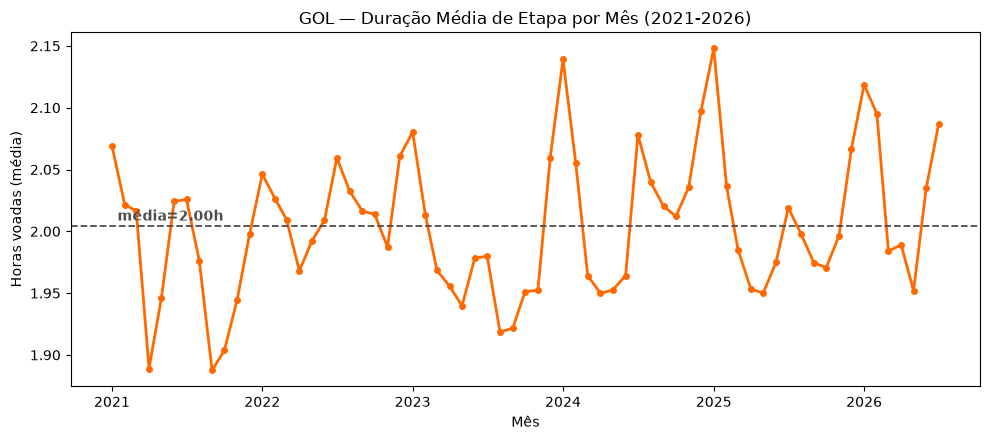

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.5))

ax.plot(mensal.index, mensal.values, color="#FF6900", linewidth=2, marker="o", markersize=4)
ax.axhline(media_geral, color="#4d4d4d", linestyle="--", linewidth=1.3)
ax.annotate(
    f"média={media_geral:.2f}h", xy=(mensal.index[0], media_geral),
    xytext=(4, 4), textcoords="offset points", color="#4d4d4d", fontweight="bold",
)

ax.set_title("GOL — Duração Média de Etapa por Mês (2021-2026)")
ax.set_xlabel("Mês")
ax.set_ylabel("Horas voadas (média)")
fig.tight_layout()

## 5. O mesmo gráfico em seaborn: dado "long-form"

seaborn prefere dado em formato **longo** (long-form): uma linha por observação, colunas
identificam o quê é cada valor. `mensal` é uma `Series` indexada por data — para virar long-form
precisa só de `.reset_index()`, que transforma o índice em coluna.

Com dado long-form, `sns.lineplot(data=..., x=, y=)` substitui as ~4 linhas de `ax.plot` +
`ax.axhline` manuais. A faixa sombreada é o intervalo de confiança — aqui não aparece porque só
há um ponto por mês (nada para o seaborn calcular incerteza em cima).

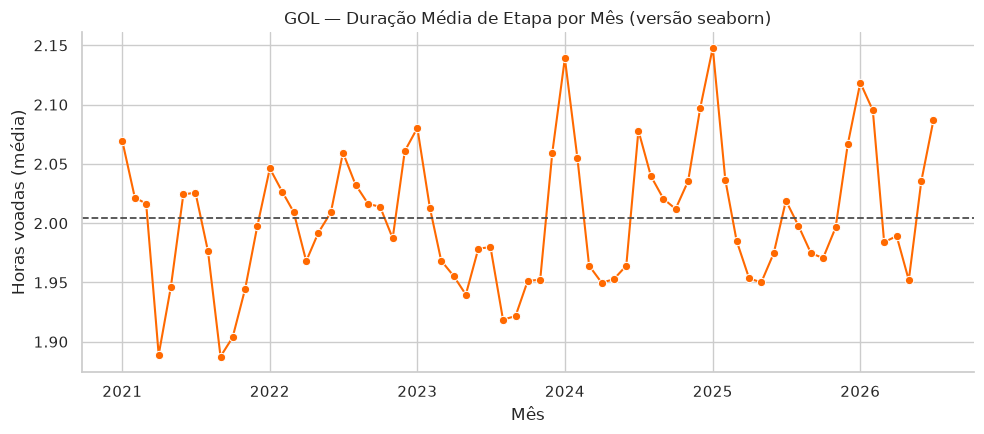

In [10]:
mensal_long = mensal.reset_index(name="duracao_media")
mensal_long.columns = ["mes", "duracao_media"]

sns.set_theme(style="whitegrid")  # a partir daqui, isso tambem vira o padrao do matplotlib puro

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.lineplot(data=mensal_long, x="mes", y="duracao_media", color="#FF6900", marker="o", ax=ax)
ax.axhline(media_geral, color="#4d4d4d", linestyle="--", linewidth=1.3)
ax.set_title("GOL — Duração Média de Etapa por Mês (versão seaborn)")
ax.set_xlabel("Mês")
ax.set_ylabel("Horas voadas (média)")
sns.despine(ax=ax)
fig.tight_layout()

## 6. Cruzamento tempo x frota: `groupby` de duas chaves e o parâmetro `hue`

Aqui aparece a maior diferença prática entre as duas bibliotecas. Em matplotlib puro, "uma linha
por categoria" é um loop explícito: filtra o modelo, agrega, desenha, próximo modelo. Em seaborn,
o parâmetro `hue` faz esse loop por você, desde que o dado já esteja em long-form com uma coluna
identificando a categoria.

Primeiro, filtramos para modelos com volume relevante (o mesmo corte de `>= 1000` etapas no
período inteiro do script original) e agregamos com `groupby([...]).resample(...)` — agrupar por
categoria *e* por tempo ao mesmo tempo.

In [11]:
contagem_modelo = df["sg_equipamento_icao"].value_counts()
modelos_relevantes = contagem_modelo[contagem_modelo >= 1000].index

df_frota = df[df["sg_equipamento_icao"].isin(modelos_relevantes)]

mensal_frota = (
    df_frota
    .set_index("dt_partida_real")
    .groupby("sg_equipamento_icao")["nr_horas_voadas"]
    .resample("MS")
    .mean()
    .reset_index(name="duracao_media")
)
mensal_frota.head()

,sg_equipamento_icao,dt_partida_real,duracao_media
0,B38M,2021-01-01,2.511350
1,B38M,2021-02-01,2.578377
2,B38M,2021-03-01,2.404469
3,B38M,2021-04-01,2.194647
4,B38M,2021-05-01,2.326681


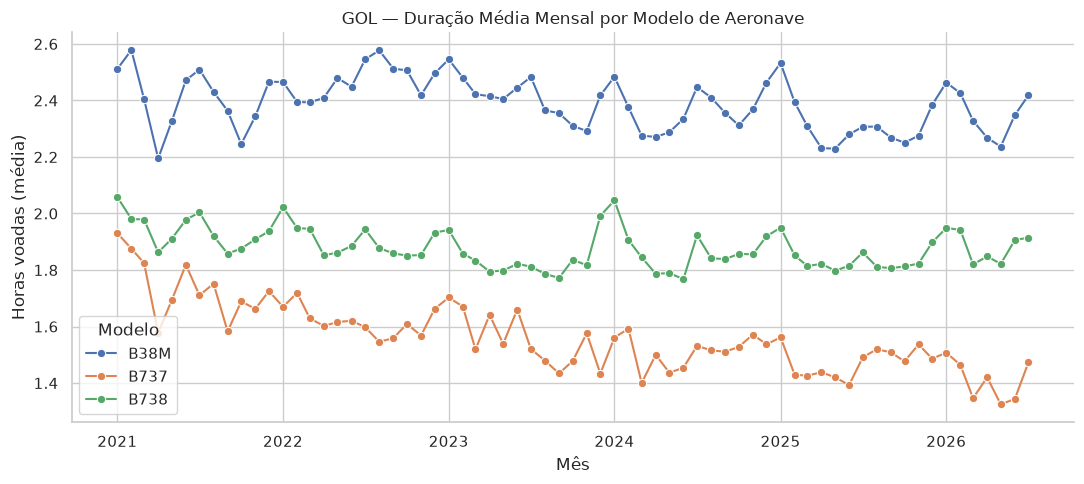

In [12]:
fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(
    data=mensal_frota, x="dt_partida_real", y="duracao_media",
    hue="sg_equipamento_icao", marker="o", ax=ax,
)
ax.set_title("GOL — Duração Média Mensal por Modelo de Aeronave")
ax.set_xlabel("Mês")
ax.set_ylabel("Horas voadas (média)")
ax.legend(title="Modelo", frameon=True)
sns.despine(ax=ax)
fig.tight_layout()

## 7. Barras agrupadas: agregação manual vs. agregação automática

O script original calcula a média por (modelo, natureza) com `groupby(...).agg(["mean", "count"])`
e desenha as barras lado a lado calculando o deslocamento (`largura`) na mão — é o jeito
matplotlib.

`sns.barplot` faz a agregação sozinho: passa o `DataFrame` **não agregado** e ele calcula a
média por grupo internamente (parâmetro `estimator`), já desenhando as barras lado a lado quando
se usa `hue`. A troca é controle fino por conveniência — aqui desligamos a barra de erro
(`errorbar=None`) para reproduzir exatamente a média simples do script original, sem intervalo
de confiança por bootstrap.

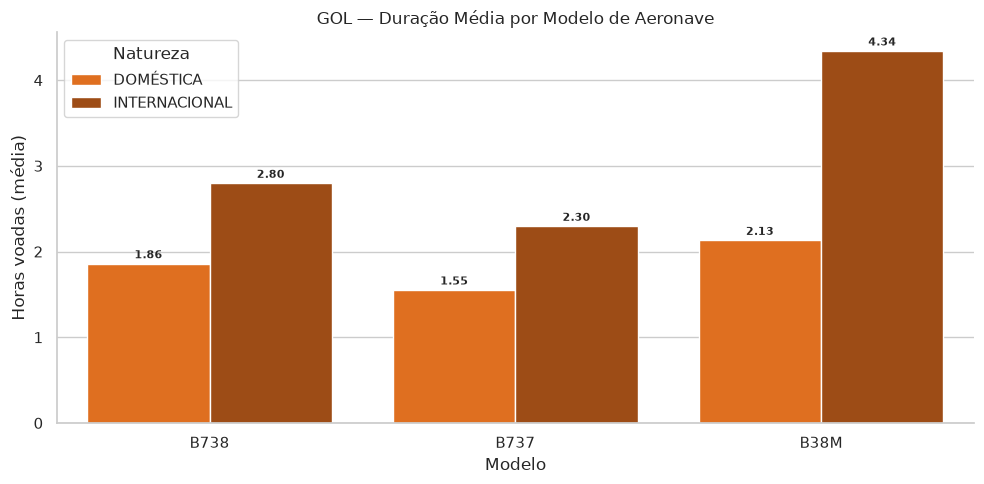

In [13]:
contagem_modelo_nat = df.groupby(["sg_equipamento_icao", "ds_natureza_tipo_linha"])["nr_horas_voadas"].transform("count")
df_barras = df[contagem_modelo_nat >= 30]

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=df_barras, x="sg_equipamento_icao", y="nr_horas_voadas",
    hue="ds_natureza_tipo_linha", estimator=np.mean, errorbar=None,
    palette=["#FF6900", "#B34700"], ax=ax,
)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.2f", fontweight="bold", fontsize=8, padding=2)

ax.set_title("GOL — Duração Média por Modelo de Aeronave")
ax.set_xlabel("Modelo")
ax.set_ylabel("Horas voadas (média)")
ax.legend(title="Natureza")
sns.despine(ax=ax)
fig.tight_layout()

## 8. Regra de HUB (Pareto 80%): `cumsum` do numpy por trás do `.cumsum()` do pandas

A regra da SPEC-013 para achar bases HUB: ordena as bases por volume decrescente e considera HUB
enquanto o acumulado **antes** daquela base ainda for menor que 80% do total. `pd.Series.cumsum()`
é a soma acumulada — chama `numpy.cumsum` por baixo. Um exemplo pequeno antes de aplicar na base
real deixa a mecânica visível:

In [14]:
exemplo = np.array([50, 30, 10, 6, 4])
exemplo_pct = 100 * exemplo / exemplo.sum()
exemplo_pct_acum = np.cumsum(exemplo_pct)

for valor, pct, acum in zip(exemplo, exemplo_pct, exemplo_pct_acum):
    print(f"valor={valor:>3}  pct={pct:5.1f}%  acumulado_ate_aqui={acum:5.1f}%")

valor= 50  pct= 50.0%  acumulado_ate_aqui= 50.0%
valor= 30  pct= 30.0%  acumulado_ate_aqui= 80.0%
valor= 10  pct= 10.0%  acumulado_ate_aqui= 90.0%
valor=  6  pct=  6.0%  acumulado_ate_aqui= 96.0%
valor=  4  pct=  4.0%  acumulado_ate_aqui=100.0%


In [15]:
def selecionar_hub(contagens: pd.Series) -> pd.Series:
    """HUB enquanto o acumulado ANTES da base for < 80% (SPEC-013 Sec.6.5)."""
    ordenado = contagens.sort_values(ascending=False)
    pct = 100 * ordenado / ordenado.sum()
    pct_acum = pct.cumsum()
    pct_acum_antes = pct_acum - pct
    return ordenado[pct_acum_antes < 80]


contagem_origem = df["sg_icao_origem"].value_counts()
bases_hub = selecionar_hub(contagem_origem)
print(f"{len(bases_hub)} bases HUB de {contagem_origem.shape[0]} bases totais")
bases_hub

16 bases HUB de 141 bases totais


sg_icao_origem
SBSP    176657
SBGR    173549
SBBR    106202
SBGL     89070
SBRJ     65450
SBSV     64276
SBCF     39289
SBPA     33659
SBRF     30512
SBFZ     29055
SBFL     28040
SBCT     28020
SBGO     19621
SBVT     18789
SBNF     17537
SBMO     17388
Name: count, dtype: int64

## 9. Barras horizontais com cor contínua: por que aqui o matplotlib puro ganha

Queremos codificar duas informações na mesma barra: comprimento = nº de etapas, cor = duração
média. Isso é um mapeamento **contínuo** de cor (`Normalize` + `Colormap` + `colorbar`), não uma
categoria. `sns.barplot` colore por categoria (`hue`), não por um valor numérico contínuo com
barra de escala — para esse caso específico, a API de baixo nível do matplotlib é a ferramenta
certa, não uma limitação a contornar.

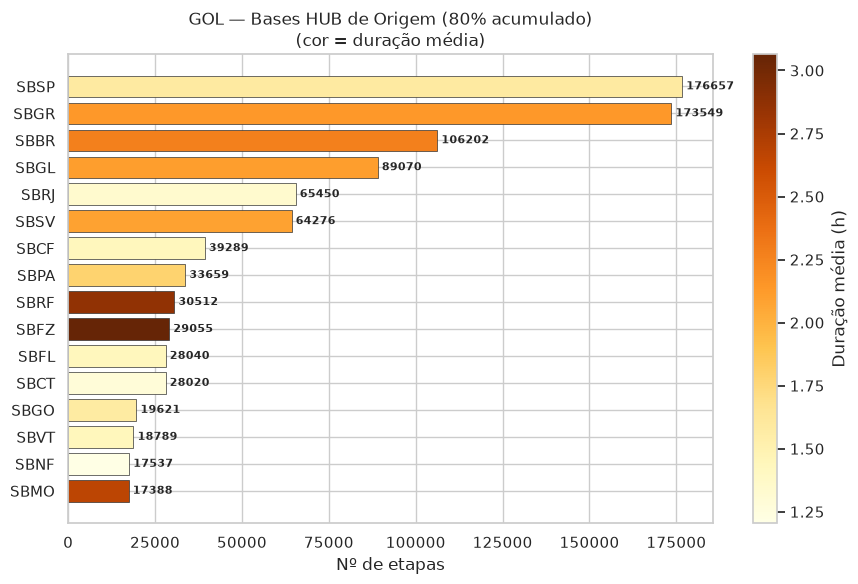

In [16]:
agg_bases = (
    df.groupby("sg_icao_origem")["nr_horas_voadas"]
    .agg(n_etapas="count", duracao_media="mean")
    .loc[bases_hub.index]
    .sort_values("n_etapas")
)

norm = plt.Normalize(agg_bases["duracao_media"].min(), agg_bases["duracao_media"].max())
cmap = plt.get_cmap("YlOrBr")
cores = cmap(norm(agg_bases["duracao_media"]))

fig, ax = plt.subplots(figsize=(9, 6))
barras = ax.barh(agg_bases.index, agg_bases["n_etapas"], color=cores, edgecolor="#333333", linewidth=0.5)
ax.bar_label(barras, fmt="%.0f", fontweight="bold", fontsize=8, padding=3)
ax.set_title("GOL — Bases HUB de Origem (80% acumulado)\n(cor = duração média)")
ax.set_xlabel("Nº de etapas")

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax)
cbar.set_label("Duração média (h)")
fig.tight_layout()

## 10. Heatmap: um tipo de gráfico que o seaborn resolve melhor que ninguém

Última peça, sem equivalente no script original: mês x modelo, cor = duração média. Isso exige
uma tabela em formato **largo** (uma linha por mês, uma coluna por modelo) — o oposto do
long-form usado até aqui. `pivot_table` faz essa transposição; `sns.heatmap` desenha a matriz
resultante direto, com `annot=True` escrevendo o valor em cada célula.

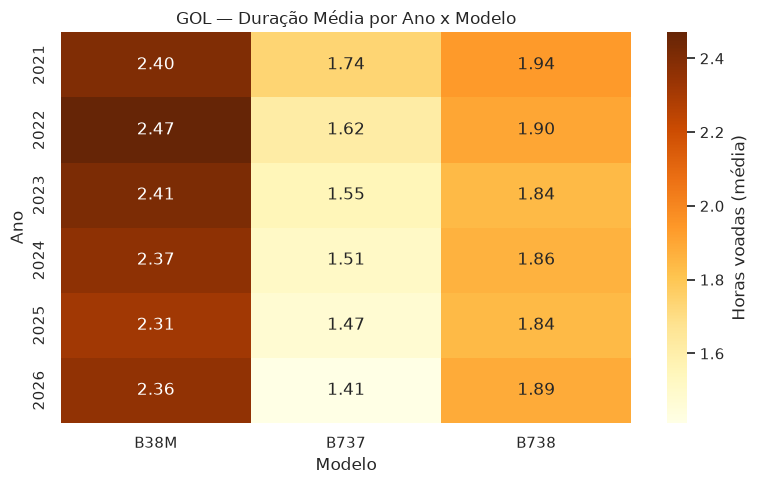

In [17]:
pivot_mes_modelo = mensal_frota.pivot_table(
    index="dt_partida_real", columns="sg_equipamento_icao", values="duracao_media"
)
# um heatmap com 65+ meses fica ilegivel -- reduzir para media por ano X modelo
pivot_ano_modelo = (
    mensal_frota.assign(ano=mensal_frota["dt_partida_real"].dt.year)
    .pivot_table(index="ano", columns="sg_equipamento_icao", values="duracao_media", aggfunc="mean")
)

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(pivot_ano_modelo, annot=True, fmt=".2f", cmap="YlOrBr", cbar_kws={"label": "Horas voadas (média)"}, ax=ax)
ax.set_title("GOL — Duração Média por Ano x Modelo")
ax.set_xlabel("Modelo")
ax.set_ylabel("Ano")
fig.tight_layout()

## Recapitulando

| Biblioteca | Conceito | Onde apareceu |
|---|---|---|
| pandas | `read_sql_query`, `parse_dates` | Seção 2 |
| pandas | `.info()`, `.describe()`, `.dtypes` | Seção 2 |
| numpy | `mean`/`median`/`std`/`percentile`, vetorização vs. loop | Seção 3 |
| pandas | `set_index` + `resample("MS")` | Seção 4 |
| matplotlib | `Figure`/`Axes`, `ax.plot`, `ax.axhline`, `ax.annotate` | Seção 4 |
| seaborn | dado long-form, `sns.lineplot`, `sns.despine` | Seção 5 |
| pandas | `groupby([...]).resample(...)`, `.isin()` | Seção 6 |
| seaborn | `hue` substitui loop manual por categoria | Seção 6 |
| matplotlib | barras agrupadas manuais (`largura`, deslocamento) | Seção 7 |
| seaborn | `sns.barplot` com agregação e `hue` automáticos | Seção 7 |
| numpy/pandas | `cumsum`, regra de Pareto 80% | Seção 8 |
| matplotlib | `Normalize` + `Colormap` + `colorbar` (cor contínua) | Seção 9 |
| pandas | `pivot_table` (long-form → wide-form) | Seção 10 |
| seaborn | `sns.heatmap` | Seção 10 |

**Sobre este notebook vs. o script de produção**: `analise_etapa_media_gol.py` continua sendo o
artefato canônico da SPEC-013 (gera as figuras oficiais em `a4_figuras_gol/`). Este notebook é um
material de estudo derivado da mesma análise — não substitui o script nem grava PNGs de produção.